# Property Address Classification

The goal here is pretty straightforward — given a raw property address string, predict which category it falls into:
- `flat` (apartments, flats in residential buildings)
- `houseorplot` (independent houses, plots, villas)
- `landparcel` (raw land, agricultural land, survey entries)
- `commercial unit` (shops, offices, showrooms, warehouses)
- `others` (ambiguous, broken, or unclassifiable entries)

I'm going to try multiple approaches and see what works best:
1. Traditional ML classifiers on TF-IDF features (Logistic Regression, SVM, Naive Bayes, Random Forest, XGBoost, etc.)
2. A BiLSTM with attention mechanism (PyTorch)
3. Fine-tuning DistilBERT (HuggingFace Transformers)

Let's start by loading the data and understanding what we're working with.

In [1]:
import os, re, random, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from xgboost import XGBClassifier

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Running on: {device}")

OUTPUT_DIR = "/kaggle/working/saved_models"
os.makedirs(OUTPUT_DIR, exist_ok=True)

Running on: cuda


In [2]:
# Loading the dataset
df = pd.read_csv("/kaggle/input/datasets/itsavinashverma/task-dataset-dataset-csv/task_dataset - dataset.csv")

print(f"Shape: {df.shape}")
print(f"Columns: {list(df.columns)}")
print(f"\nAny nulls?")
print(df.isnull().sum())

Shape: (11803, 2)
Columns: ['property_address', 'categories']

Any nulls?
property_address    0
categories          0
dtype: int64


## Exploratory Data Analysis

Before jumping into modeling, let me understand the data — what do these addresses look like, how are the classes distributed, are there any obvious data quality issues?

Class distribution:

categories
flat               4076
houseorplot        3585
others             1526
commercial unit    1360
landparcel         1256
Name: count, dtype: int64

Total samples: 11803


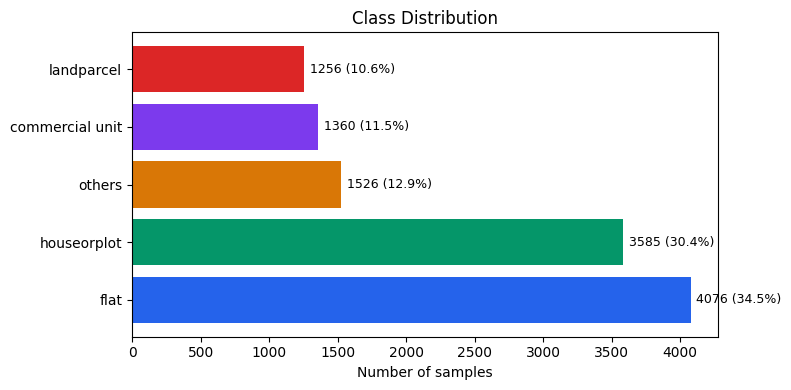

In [3]:
# Class distribution
print("Class distribution:\n")
print(df['categories'].value_counts())
print(f"\nTotal samples: {len(df)}")

fig, ax = plt.subplots(figsize=(8, 4))
counts = df['categories'].value_counts()
bars = ax.barh(counts.index, counts.values, color=['#2563eb','#059669','#d97706','#7c3aed','#dc2626'])
ax.set_xlabel('Number of samples')
ax.set_title('Class Distribution')
for bar, val in zip(bars, counts.values):
    ax.text(bar.get_width() + 40, bar.get_y() + bar.get_height()/2,
            f'{val} ({val/len(df)*100:.1f}%)', va='center', fontsize=9)
plt.tight_layout()
plt.show()

# The dataset is somewhat imbalanced - flat has ~34% while landparcel has only ~10%
# I'll need to handle this with class_weight='balanced' in the models

In [4]:
# Let's look at some actual addresses to understand the patterns
print("=" * 70)
for cat in df['categories'].unique():
    subset = df[df['categories'] == cat]
    print(f"\n--- {cat.upper()} (sample addresses) ---")
    for i in range(min(3, len(subset))):
        addr = str(subset['property_address'].iloc[i])
        print(f"  {addr[:120]}{'...' if len(addr) > 120 else ''}")
    print()


--- HOUSEORPLOT (sample addresses) ---
  South Part Of Plot No. 107 (Old Plot No. 87) And North Part Of Plot No.106 (Old Plot No. 
 01), Scheme Jamana Vihar, Te...
  Plot No: 284/Part, Eastern Side Portion, Sy Nos: 993/45/A, 993/44, Patancheru Mandal, Medak Dist, Ameenpoor Village, Med...
  Duplex House On Plot No. 67 Part, Sy Nos. 127, 139 
 Part And 142, Sai Krishna Enclave, Phase-Ii, Yapral Village, Under...


--- FLAT (sample addresses) ---
  Flat-301,Floor-3 Atulya Residency - A -Wing S No 89, 90,Block 87,Sub Plotno - B, Fp 75 Tp 85(Sarthana-Pasodara-Laskana)S...
  1706 4A Elara Chs, Jp North Elara Mira Road Thane 401207
  903 9 A Wing Millennium Samriddhi Sr No 31 32 A 5 31 32 A 6 31 32 A 7Kate Wasti Road Na Punawale Pune Pune Maharashtra 4...


--- COMMERCIAL UNIT (sample addresses) ---
  Stall No -850(Shop) Plot No:- 523 To 422 , Sub Plot No:- 768 To 888/ 953 Shradhha Complex(Shivam Park) Off Sadhu Vasvani...
  Shop Room, Ground Floor, South West Side, Ground, Na, Rudrani, Rud

Address length statistics:
count    11803.000000
mean       145.208845
std         85.364184
min          4.000000
25%         94.000000
50%        128.000000
75%        167.000000
max       1004.000000
Name: addr_len, dtype: float64


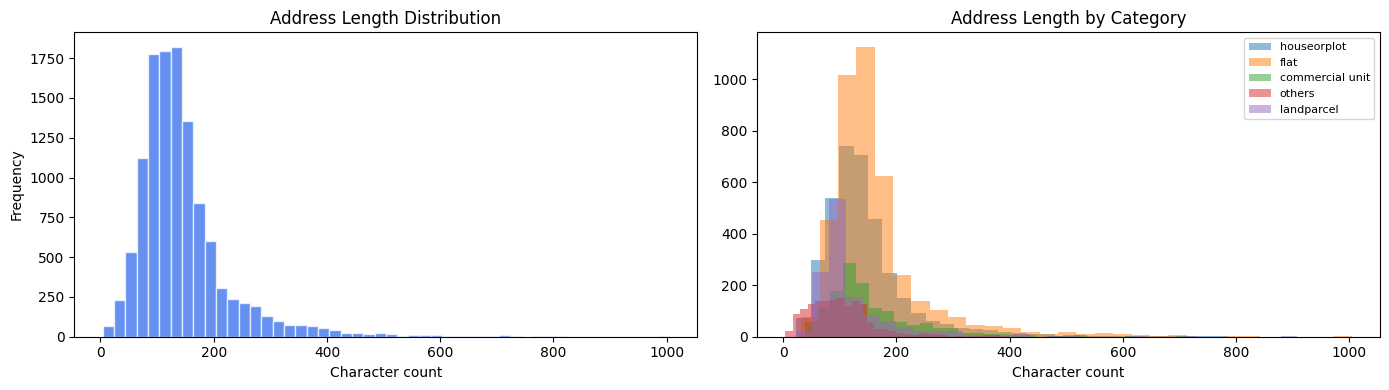


Looking for suspicious entries...
JSON error entries: 6
  Example: {"status": "error"}
Very short addresses (< 10 chars): 12
  'top up' -> others
  'Na Na' -> others
  'tenpair' -> others
  'Test' -> others
  'test' -> others

Addresses with embedded newlines: 1692


In [5]:
# Check for potential data quality issues

# 1. Address length distribution
df['addr_len'] = df['property_address'].astype(str).apply(len)
print("Address length statistics:")
print(df['addr_len'].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Overall length distribution
axes[0].hist(df['addr_len'], bins=50, color='#2563eb', alpha=0.7, edgecolor='white')
axes[0].set_title('Address Length Distribution')
axes[0].set_xlabel('Character count')
axes[0].set_ylabel('Frequency')

# Length by category
for cat in df['categories'].unique():
    subset = df[df['categories'] == cat]
    axes[1].hist(subset['addr_len'], bins=30, alpha=0.5, label=cat)
axes[1].set_title('Address Length by Category')
axes[1].set_xlabel('Character count')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

# 2. Check for weird entries
print("\nLooking for suspicious entries...")
suspicious = df[df['property_address'].astype(str).str.contains('status.*error', case=False, na=False)]
print(f"JSON error entries: {len(suspicious)}")
if len(suspicious) > 0:
    print(f"  Example: {suspicious['property_address'].iloc[0]}")

short = df[df['addr_len'] < 10]
print(f"Very short addresses (< 10 chars): {len(short)}")
if len(short) > 0:
    for _, row in short.head(5).iterrows():
        print(f"  '{row['property_address']}' -> {row['categories']}")

# 3. Check for embedded newlines/tabs (common in scraped data)
has_newlines = df['property_address'].astype(str).str.contains('\\n|\n', regex=True).sum()
print(f"\nAddresses with embedded newlines: {has_newlines}")

df.drop('addr_len', axis=1, inplace=True)

## Data Cleaning & Preprocessing

Looking at the data above, there are several issues I need to handle:
- Some entries are just JSON error strings like `{"status": "error"}`
- Many addresses have embedded `\n` and `\t` characters
- Mixed casing everywhere
- Lots of abbreviations (Sy. No., Opp, Nr, Vill, etc.)
- Special characters that don't help with classification

I'll build a cleaning function that handles all of these step by step.

In [6]:
def clean_address(text):
    """Clean a raw property address string for classification."""

    # handle nulls
    if pd.isna(text) or not isinstance(text, str):
        return ""

    text = text.strip()

    # some entries are literally JSON error responses — useless
    if text.startswith('{') and 'status' in text.lower():
        return ""

    # clean up embedded newlines and tabs (very common in this dataset)
    text = text.replace('\n', ' ').replace('\r', ' ').replace('\t', ' ')

    # lowercase everything
    text = text.lower()

    # expand common abbreviations found in Indian property addresses
    # this helps the model see consistent terms instead of dozens of variants
    abbrevs = {
        r'\bsy\.?\s*no\.?': 'survey number',
        r'\bs\.?\s*no\.?': 'survey number',
        r'\bkh\.?\s*no\.?': 'khasra number',
        r'\bsr\.?\s*no\.?': 'survey number',
        r'\bopp\.?\b': 'opposite',
        r'\bnr\.?\b': 'near',
        r'\bvill\.?\b': 'village',
        r'\bdist\.?\b': 'district',
        r'\bteh\.?\b': 'tehsil',
        r'\bsq\.?\s*ft\.?': 'sqft',
        r'\bsq\.?\s*mt\.?': 'sqmt',
        r'\bsq\.?\s*yd\.?': 'sqyd',
    }
    for pattern, replacement in abbrevs.items():
        text = re.sub(pattern, replacement, text)

    # remove special characters but keep slashes and hyphens
    # (they carry meaning: flat 303/A, A-wing, plot-45)
    text = re.sub(r'[^a-z0-9/\-\s]', ' ', text)

    # collapse multiple spaces
    text = re.sub(r'\s+', ' ', text).strip()

    # if nothing meaningful is left, return empty
    if len(text) < 3:
        return ""

    return text


# apply cleaning
df['cleaned'] = df['property_address'].apply(clean_address)

# drop rows that ended up empty
before = len(df)
df = df[df['cleaned'].str.len() > 0].reset_index(drop=True)
print(f"Dropped {before - len(df)} empty/invalid rows")
print(f"Clean dataset: {len(df)} samples")

Dropped 6 empty/invalid rows
Clean dataset: 11797 samples


In [7]:
# Let's see what the cleaning did — before vs after
print("Cleaning examples:\n")
for i in [0, 5, 10, 50, 100]:
    if i < len(df):
        raw = str(df['property_address'].iloc[i])
        clean = df['cleaned'].iloc[i]
        cat = df['categories'].iloc[i]
        print(f"[{cat}]")
        print(f"  Before: {raw[:100]}{'...' if len(raw)>100 else ''}")
        print(f"  After:  {clean[:100]}{'...' if len(clean)>100 else ''}")
        print()

Cleaning examples:

[houseorplot]
  Before: South Part Of Plot No. 107 (Old Plot No. 87) And North Part Of Plot No.106 (Old Plot No. 
 01), Sch...
  After:  south part of plot no 107 old plot no 87 and north part of plot no 106 old plot no 01 scheme jamana ...

[houseorplot]
  Before: Plot No: 284/Part, Eastern Side Portion, Sy Nos: 993/45/A, 993/44, Patancheru Mandal, Medak Dist, Am...
  After:  plot no 284/part eastern side portion survey numbers 993/45/a 993/44 patancheru mandal medak distric...

[landparcel]
  Before: Sy. No. 1388/1, Mandal Mangalagiri, Near Old Shiv Mandir, Chengalpattu, Tamil Nadu - 617093
  After:  survey number 1388/1 mandal mangalagiri near old shiv mandir chengalpattu tamil nadu - 617093

[flat]
  Before: Golden Heights , Flat No. 703, Fourth Floor, Block No. I, K. C. Choudhury Road, Near Himatsingka Pow...
  After:  golden heights flat no 703 fourth floor block no i k c choudhury road near himatsingka power energy ...

[others]
  Before: Gpn No 624,-,Mali Ga

Token count stats (after cleaning):
count    11797.000000
mean        22.782657
std         14.463617
min          1.000000
25%         14.000000
50%         19.000000
75%         26.000000
max        171.000000
Name: cleaned, dtype: float64

95th percentile: 50 tokens
99th percentile: 81 tokens


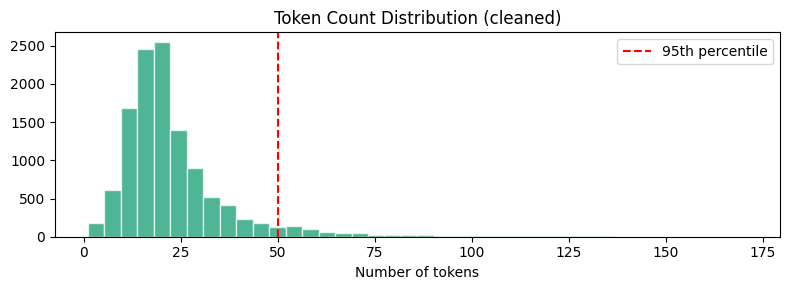

In [8]:
# Cleaned text length distribution (to decide max_len for neural models later)
clean_lens = df['cleaned'].str.split().apply(len)
print("Token count stats (after cleaning):")
print(clean_lens.describe())
print(f"\n95th percentile: {clean_lens.quantile(0.95):.0f} tokens")
print(f"99th percentile: {clean_lens.quantile(0.99):.0f} tokens")

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(clean_lens, bins=40, color='#059669', alpha=0.7, edgecolor='white')
ax.axvline(clean_lens.quantile(0.95), color='red', linestyle='--', label='95th percentile')
ax.set_title('Token Count Distribution (cleaned)')
ax.set_xlabel('Number of tokens')
ax.legend()
plt.tight_layout()
plt.show()

# Most addresses are under ~40-50 tokens, so I'll use that as max_len

In [9]:
# Encode labels and split the data
le = LabelEncoder()
df['label'] = le.fit_transform(df['categories'])

# stratified split to maintain class proportions in both sets
X_train, X_test, y_train, y_test = train_test_split(
    df['cleaned'], df['label'],
    test_size=0.2, stratify=df['label'], random_state=SEED
)

X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

print(f"Train: {len(X_train)} | Test: {len(X_test)}")
print(f"Label mapping: {dict(zip(le.classes_, le.transform(le.classes_)))}")

# save the encoder — we'll need it for inference later
joblib.dump(le, f"{OUTPUT_DIR}/label_encoder.joblib")

Train: 9437 | Test: 2360
Label mapping: {'commercial unit': np.int64(0), 'flat': np.int64(1), 'houseorplot': np.int64(2), 'landparcel': np.int64(3), 'others': np.int64(4)}


['/kaggle/working/saved_models/label_encoder.joblib']

## Traditional ML Models

I'll start with the classic approach: TF-IDF features + various classifiers. For property addresses, TF-IDF actually works really well because there are strong keyword signals — words like "flat", "shop", "survey", "plot" are highly discriminative.

I'm trying 6 different classifiers to see which one works best on this type of text.

In [10]:
# TF-IDF vectorization
# using word n-grams (1,2,3) to capture things like "flat no", "shop no", "survey number"
# sublinear_tf applies log scaling which works better for text classification
tfidf = TfidfVectorizer(
    analyzer='word', ngram_range=(1, 3),
    min_df=2, max_features=20000, sublinear_tf=True
)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
print(f"TF-IDF matrix shape: {X_train_tfidf.shape}")

joblib.dump(tfidf, f"{OUTPUT_DIR}/tfidf_vectorizer.joblib")

# define all the models I want to try
models = {
    "Logistic Regression": LogisticRegression(
        class_weight='balanced', max_iter=1000, C=1.0, solver='lbfgs', random_state=SEED),

    "Linear SVM": CalibratedClassifierCV(
        LinearSVC(class_weight='balanced', max_iter=3000, C=1.0, random_state=SEED), cv=3),

    "Multinomial NB": MultinomialNB(alpha=0.1),

    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight='balanced', random_state=SEED, n_jobs=-1),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200, max_depth=5, learning_rate=0.1, random_state=SEED),

    "XGBoost": XGBClassifier(
        n_estimators=200, max_depth=6, learning_rate=0.1,
        eval_metric='mlogloss', verbosity=0, random_state=SEED),
}

# train and evaluate each one
ml_results = {}
print(f"\n{'Model':<25s} | {'Accuracy':>8s} | {'Macro F1':>8s} | {'Time':>6s}")
print("-" * 55)

for name, model in models.items():
    t0 = time.time()
    model.fit(X_train_tfidf, y_train)
    preds = model.predict(X_test_tfidf)
    elapsed = time.time() - t0

    f1 = f1_score(y_test, preds, average='macro')
    acc = accuracy_score(y_test, preds)
    ml_results[name] = {"model": model, "y_pred": preds, "f1": f1, "acc": acc}
    print(f"{name:<25s} | {acc:>8.4f} | {f1:>8.4f} | {elapsed:>5.1f}s")

TF-IDF matrix shape: (9437, 20000)

Model                     | Accuracy | Macro F1 |   Time
-------------------------------------------------------
Logistic Regression       |   0.8788 |   0.8630 |   5.4s
Linear SVM                |   0.8949 |   0.8767 |   0.6s
Multinomial NB            |   0.8157 |   0.7907 |   0.0s
Random Forest             |   0.8890 |   0.8697 |  51.5s
Gradient Boosting         |   0.8839 |   0.8684 | 223.4s
XGBoost                   |   0.8847 |   0.8695 |  67.0s


In [11]:
# detailed report for the best ML model
best_ml_name = max(ml_results, key=lambda k: ml_results[k]['f1'])
print(f"Best ML model: {best_ml_name} (F1 = {ml_results[best_ml_name]['f1']:.4f})")
print()
print(classification_report(y_test, ml_results[best_ml_name]['y_pred'], target_names=le.classes_))

# save the best one
joblib.dump(ml_results[best_ml_name]['model'], f"{OUTPUT_DIR}/best_ml_model.joblib")

Best ML model: Linear SVM (F1 = 0.8767)

                 precision    recall  f1-score   support

commercial unit       0.96      0.91      0.94       272
           flat       0.95      0.94      0.95       816
    houseorplot       0.86      0.90      0.88       717
     landparcel       0.81      0.73      0.76       251
         others       0.84      0.87      0.86       304

       accuracy                           0.89      2360
      macro avg       0.88      0.87      0.88      2360
   weighted avg       0.90      0.89      0.89      2360



['/kaggle/working/saved_models/best_ml_model.joblib']

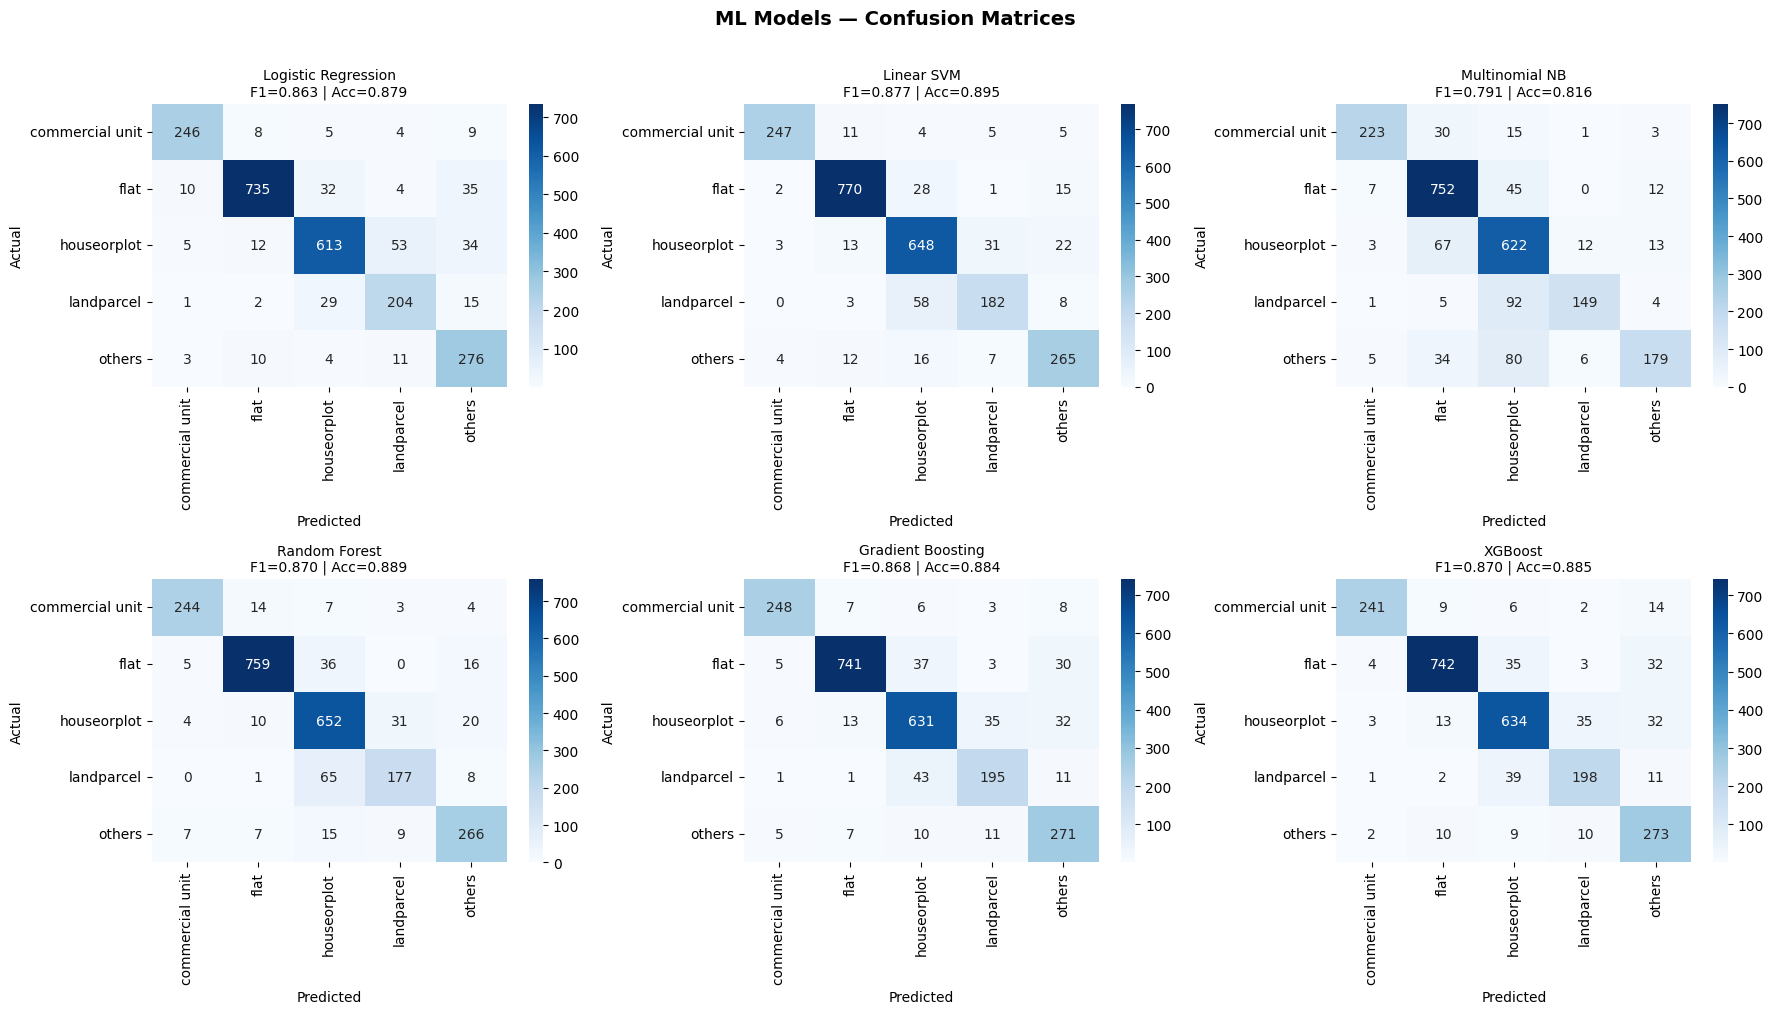

In [12]:
# confusion matrices for all 6 models
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (name, res) in zip(axes.flatten(), ml_results.items()):
    cm = confusion_matrix(y_test, res['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=le.classes_, yticklabels=le.classes_)
    ax.set_title(f"{name}\nF1={res['f1']:.3f} | Acc={res['acc']:.3f}", fontsize=10)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.suptitle('ML Models — Confusion Matrices', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/ml_confusion_matrices.png", dpi=150, bbox_inches='tight')
plt.show()

## BiLSTM with Self-Attention

Now let's try a neural approach. I'm using a Bidirectional LSTM with a self-attention layer on top. The idea is:
- The BiLSTM reads the address tokens from both directions, capturing context
- The attention layer learns to focus on the most important words (like "flat", "survey", "shop") instead of generic words like "road" or "nagar"

For regularization I'm using dropout, weight decay, and gradient clipping. I also save the best checkpoint based on validation F1 to avoid overfitting.

In [13]:
# build vocabulary from training data only
def tokenize(text):
    return re.findall(r'\b\w+\b', text.lower())

word_freq = {}
for addr in X_train:
    for w in tokenize(addr):
        word_freq[w] = word_freq.get(w, 0) + 1

# pad=0, unk=1, then all words that appear at least twice
vocab = {'<pad>': 0, '<unk>': 1}
for w in sorted(word_freq, key=word_freq.get, reverse=True):
    if word_freq[w] >= 2:
        vocab[w] = len(vocab)

MAX_LEN = 50  # covers 95%+ of addresses based on the EDA above
print(f"Vocab size: {len(vocab)}, Max length: {MAX_LEN}")

joblib.dump(vocab, f"{OUTPUT_DIR}/bilstm_vocab.joblib")

# simple dataset class
class AddressDataset(Dataset):
    def __init__(self, texts, labels, vocab, max_len):
        self.x, self.y = [], list(labels)
        for t in texts:
            ids = [vocab.get(w, 1) for w in tokenize(t)]
            ids = (ids + [0]*max_len)[:max_len]
            self.x.append(torch.tensor(ids, dtype=torch.long))
    def __len__(self): return len(self.x)
    def __getitem__(self, i): return self.x[i], torch.tensor(self.y[i], dtype=torch.long)

train_ds = AddressDataset(X_train, y_train, vocab, MAX_LEN)
test_ds = AddressDataset(X_test, y_test, vocab, MAX_LEN)
train_dl = DataLoader(train_ds, batch_size=64, shuffle=True)
test_dl = DataLoader(test_ds, batch_size=64)

Vocab size: 12142, Max length: 50


In [14]:
# model definition

class Attention(nn.Module):
    """Simple additive attention — learns which timesteps matter most."""
    def __init__(self, dim):
        super().__init__()
        self.w = nn.Linear(dim, 1)
    def forward(self, x):
        weights = torch.softmax(self.w(x).squeeze(-1), dim=1)
        return torch.bmm(weights.unsqueeze(1), x).squeeze(1)

class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, n_classes):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True,
                            bidirectional=True, num_layers=2, dropout=0.3)
        self.attn = Attention(hidden_dim * 2)
        self.drop = nn.Dropout(0.4)
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, n_classes)
        )

    def forward(self, x):
        x = self.drop(self.emb(x))
        out, _ = self.lstm(x)
        out = self.attn(out)
        return self.fc(self.drop(out))

n_classes = len(le.classes_)
model = BiLSTMClassifier(len(vocab), 128, 128, n_classes).to(device)
opt = optim.Adam(model.parameters(), lr=0.002, weight_decay=1e-4)
loss_fn = nn.CrossEntropyLoss()

print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Parameters: 2,247,430


In [15]:
# training loop
EPOCHS = 15
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_f1 = 0

for epoch in range(EPOCHS):
    # train
    model.train()
    total_loss, correct, total = 0, 0, 0
    for xb, yb in train_dl:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        out = model(xb)
        loss = loss_fn(out, yb)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        total_loss += loss.item() * len(yb)
        correct += (out.argmax(1) == yb).sum().item()
        total += len(yb)

    # validate
    model.eval()
    val_loss, val_correct, val_total = 0, 0, 0
    val_preds = []
    with torch.no_grad():
        for xb, yb in test_dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            val_loss += loss_fn(out, yb).item() * len(yb)
            p = out.argmax(1)
            val_correct += (p == yb).sum().item()
            val_total += len(yb)
            val_preds.extend(p.cpu().numpy())

    tl = total_loss / len(train_ds)
    vl = val_loss / len(test_ds)
    ta = correct / total
    va = val_correct / val_total
    vf1 = f1_score(y_test, val_preds, average='macro')

    history['train_loss'].append(tl)
    history['val_loss'].append(vl)
    history['train_acc'].append(ta)
    history['val_acc'].append(va)

    # save best checkpoint
    if vf1 > best_f1:
        best_f1 = vf1
        torch.save(model.state_dict(), f"{OUTPUT_DIR}/bilstm_best.pth")

    if (epoch+1) % 3 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:2d}/{EPOCHS} — "
              f"train_loss: {tl:.4f}, train_acc: {ta:.4f} | "
              f"val_loss: {vl:.4f}, val_acc: {va:.4f}, val_f1: {vf1:.4f}")

# load best weights back
model.load_state_dict(torch.load(f"{OUTPUT_DIR}/bilstm_best.pth", weights_only=True))
model.to(device)
print(f"\nBest checkpoint restored (F1 = {best_f1:.4f})")

Epoch  1/15 — train_loss: 0.9258, train_acc: 0.6407 | val_loss: 0.5367, val_acc: 0.8169, val_f1: 0.7783
Epoch  3/15 — train_loss: 0.4133, train_acc: 0.8616 | val_loss: 0.4001, val_acc: 0.8602, val_f1: 0.8304
Epoch  6/15 — train_loss: 0.2800, train_acc: 0.9066 | val_loss: 0.3326, val_acc: 0.8903, val_f1: 0.8709
Epoch  9/15 — train_loss: 0.2079, train_acc: 0.9295 | val_loss: 0.3349, val_acc: 0.8898, val_f1: 0.8734
Epoch 12/15 — train_loss: 0.1572, train_acc: 0.9478 | val_loss: 0.3563, val_acc: 0.8962, val_f1: 0.8796
Epoch 15/15 — train_loss: 0.1259, train_acc: 0.9558 | val_loss: 0.3845, val_acc: 0.8996, val_f1: 0.8833

Best checkpoint restored (F1 = 0.8886)


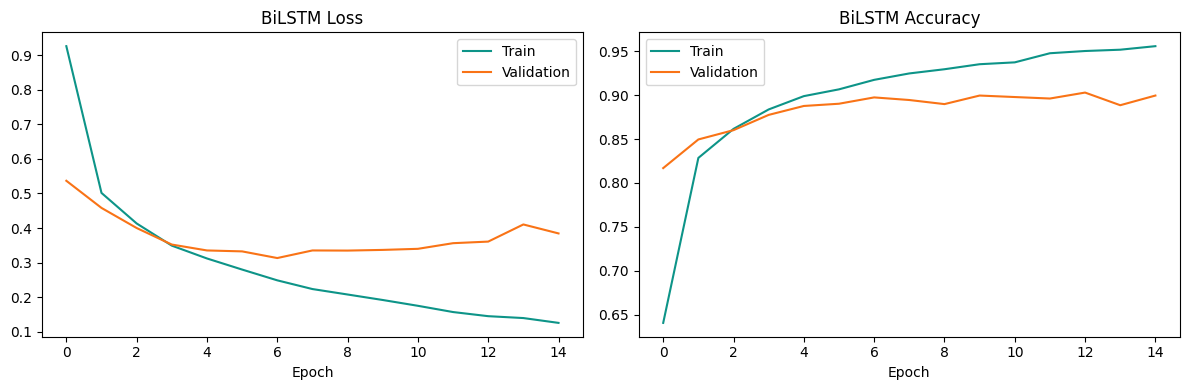

In [16]:
# training curves — this helps diagnose overfitting/underfitting
# if train_loss keeps dropping but val_loss starts going up, that's overfitting
# if both stay high and flat, that's underfitting

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history['train_loss'], label='Train', color='#0d9488')
ax1.plot(history['val_loss'], label='Validation', color='#f97316')
ax1.set_title('BiLSTM Loss')
ax1.set_xlabel('Epoch')
ax1.legend()

ax2.plot(history['train_acc'], label='Train', color='#0d9488')
ax2.plot(history['val_acc'], label='Validation', color='#f97316')
ax2.set_title('BiLSTM Accuracy')
ax2.set_xlabel('Epoch')
ax2.legend()
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/bilstm_curves.png", dpi=150, bbox_inches='tight')
plt.show()

BiLSTM — Accuracy: 0.9030, Macro F1: 0.8886

                 precision    recall  f1-score   support

commercial unit       0.96      0.91      0.93       272
           flat       0.95      0.95      0.95       816
    houseorplot       0.89      0.89      0.89       717
     landparcel       0.81      0.81      0.81       251
         others       0.85      0.88      0.86       304

       accuracy                           0.90      2360
      macro avg       0.89      0.89      0.89      2360
   weighted avg       0.90      0.90      0.90      2360



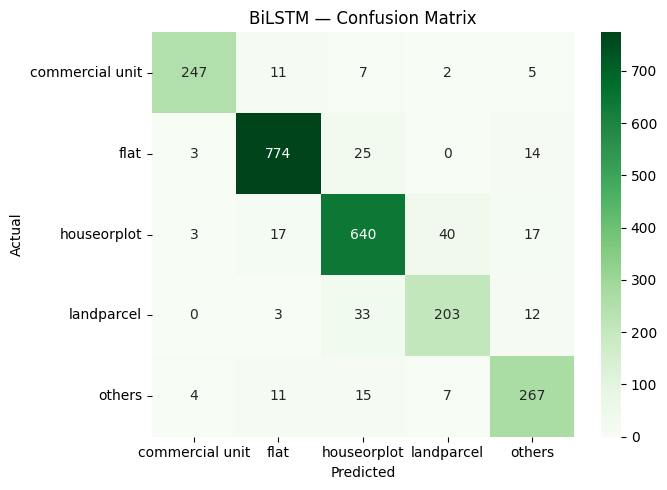

In [17]:
# evaluate on test set
model.eval()
y_pred_lstm = []
with torch.no_grad():
    for xb, _ in test_dl:
        y_pred_lstm.extend(model(xb.to(device)).argmax(1).cpu().numpy())

f1_lstm = f1_score(y_test, y_pred_lstm, average='macro')
acc_lstm = accuracy_score(y_test, y_pred_lstm)
print(f"BiLSTM — Accuracy: {acc_lstm:.4f}, Macro F1: {f1_lstm:.4f}")
print()
print(classification_report(y_test, y_pred_lstm, target_names=le.classes_))

cm = confusion_matrix(y_test, y_pred_lstm)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('BiLSTM — Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/bilstm_cm.png", dpi=150, bbox_inches='tight')
plt.show()

## DistilBERT Fine-Tuning

Finally, let's try a transformer model. I'm using DistilBERT — it's basically a compressed version of BERT that's 40% smaller and 60% faster but keeps ~97% of the performance. Since our training set is only ~9k samples, a smaller model is actually better here (less likely to overfit).

The idea with fine-tuning is that BERT already "knows" English from pre-training on massive corpora. We just need to teach it our specific classification task, which requires much less data than training from scratch.

In [18]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import get_linear_schedule_with_warmup

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

class BertDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.enc = tokenizer(list(texts), truncation=True, padding='max_length',
                             max_length=max_len, return_tensors='pt')
        self.labels = torch.tensor(list(labels), dtype=torch.long)
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        return {k: v[i] for k, v in self.enc.items()}, self.labels[i]

bert_train = BertDataset(X_train, y_train, tokenizer)
bert_test = BertDataset(X_test, y_test, tokenizer)
bert_train_dl = DataLoader(bert_train, batch_size=16, shuffle=True)
bert_test_dl = DataLoader(bert_test, batch_size=16)

bert_model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased", num_labels=n_classes
).to(device)

bert_opt = optim.AdamW(bert_model.parameters(), lr=2e-5, weight_decay=0.01)

BERT_EPOCHS = 4
total_steps = BERT_EPOCHS * len(bert_train_dl)
scheduler = get_linear_schedule_with_warmup(
    bert_opt, num_warmup_steps=int(0.1 * total_steps), num_training_steps=total_steps
)
print(f"DistilBERT — {sum(p.numel() for p in bert_model.parameters()):,} params, {total_steps} training steps")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT — 66,957,317 params, 2360 training steps


In [19]:
# fine-tuning loop
bert_history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_bert_f1 = 0

for epoch in range(BERT_EPOCHS):
    bert_model.train()
    total_loss, correct, total = 0, 0, 0
    for batch, labels in bert_train_dl:
        batch = {k: v.to(device) for k, v in batch.items()}
        labels = labels.to(device)
        bert_opt.zero_grad()
        out = bert_model(**batch, labels=labels)
        out.loss.backward()
        nn.utils.clip_grad_norm_(bert_model.parameters(), 1.0)
        bert_opt.step()
        scheduler.step()
        total_loss += out.loss.item() * len(labels)
        correct += (out.logits.argmax(1) == labels).sum().item()
        total += len(labels)

    bert_model.eval()
    val_loss, val_correct, val_total = 0, 0, 0
    preds = []
    with torch.no_grad():
        for batch, labels in bert_test_dl:
            batch = {k: v.to(device) for k, v in batch.items()}
            labels = labels.to(device)
            out = bert_model(**batch, labels=labels)
            val_loss += out.loss.item() * len(labels)
            p = out.logits.argmax(1)
            val_correct += (p == labels).sum().item()
            val_total += len(labels)
            preds.extend(p.cpu().numpy())

    tl = total_loss / len(bert_train)
    vl = val_loss / len(bert_test)
    ta = correct / total
    va = val_correct / val_total
    vf1 = f1_score(y_test, preds, average='macro')

    bert_history['train_loss'].append(tl)
    bert_history['val_loss'].append(vl)
    bert_history['train_acc'].append(ta)
    bert_history['val_acc'].append(va)

    if vf1 > best_bert_f1:
        best_bert_f1 = vf1
        bert_model.save_pretrained(f"{OUTPUT_DIR}/distilbert_best")
        tokenizer.save_pretrained(f"{OUTPUT_DIR}/distilbert_best")

    print(f"Epoch {epoch+1}/{BERT_EPOCHS} — "
          f"train_loss: {tl:.4f}, train_acc: {ta:.4f} | "
          f"val_loss: {vl:.4f}, val_acc: {va:.4f}, val_f1: {vf1:.4f}")

# reload best
bert_model = AutoModelForSequenceClassification.from_pretrained(
    f"{OUTPUT_DIR}/distilbert_best", num_labels=n_classes
).to(device)
print(f"\nBest DistilBERT restored (F1 = {best_bert_f1:.4f})")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 1/4 — train_loss: 0.7465, train_acc: 0.7223 | val_loss: 0.3749, val_acc: 0.8758, val_f1: 0.8577


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 2/4 — train_loss: 0.3272, train_acc: 0.8945 | val_loss: 0.3060, val_acc: 0.9000, val_f1: 0.8853


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 3/4 — train_loss: 0.2424, train_acc: 0.9261 | val_loss: 0.3042, val_acc: 0.9127, val_f1: 0.8970
Epoch 4/4 — train_loss: 0.1888, train_acc: 0.9416 | val_loss: 0.3136, val_acc: 0.9106, val_f1: 0.8954


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


Best DistilBERT restored (F1 = 0.8970)


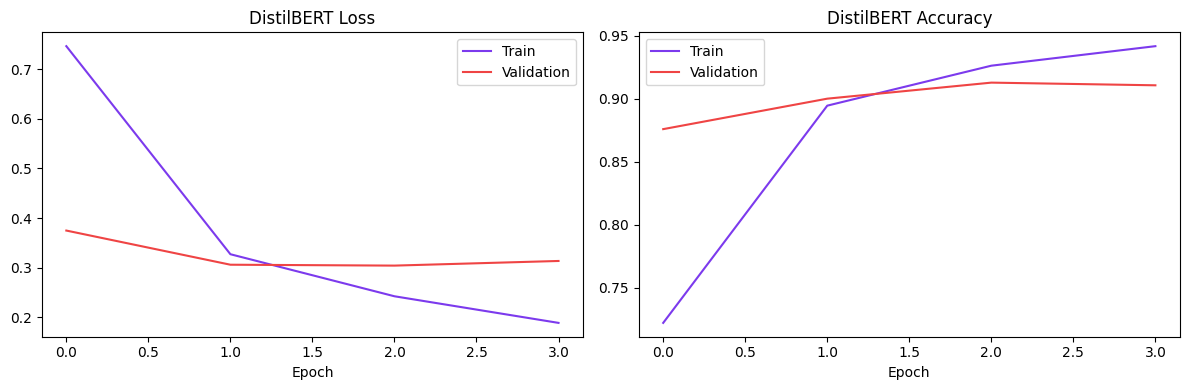

In [20]:
# training curves for BERT
# with only ~9k samples and 4 epochs, we need to watch for overfitting
# the small number of epochs + weight decay should help prevent it

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(bert_history['train_loss'], label='Train', color='#7c3aed')
ax1.plot(bert_history['val_loss'], label='Validation', color='#ef4444')
ax1.set_title('DistilBERT Loss')
ax1.set_xlabel('Epoch')
ax1.legend()

ax2.plot(bert_history['train_acc'], label='Train', color='#7c3aed')
ax2.plot(bert_history['val_acc'], label='Validation', color='#ef4444')
ax2.set_title('DistilBERT Accuracy')
ax2.set_xlabel('Epoch')
ax2.legend()
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/distilbert_curves.png", dpi=150, bbox_inches='tight')
plt.show()

DistilBERT — Accuracy: 0.9127, Macro F1: 0.8970

                 precision    recall  f1-score   support

commercial unit       0.96      0.92      0.94       272
           flat       0.96      0.95      0.95       816
    houseorplot       0.90      0.92      0.91       717
     landparcel       0.84      0.78      0.81       251
         others       0.84      0.90      0.87       304

       accuracy                           0.91      2360
      macro avg       0.90      0.89      0.90      2360
   weighted avg       0.91      0.91      0.91      2360



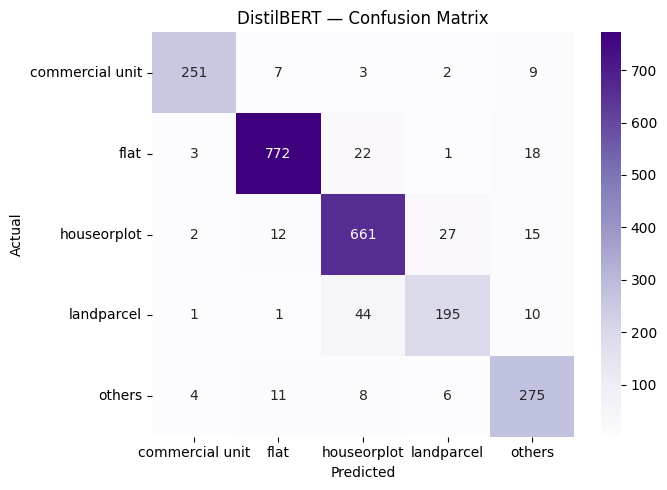

In [21]:
# evaluate
bert_model.eval()
y_pred_bert = []
with torch.no_grad():
    for batch, _ in bert_test_dl:
        batch = {k: v.to(device) for k, v in batch.items()}
        y_pred_bert.extend(bert_model(**batch).logits.argmax(1).cpu().numpy())

f1_bert = f1_score(y_test, y_pred_bert, average='macro')
acc_bert = accuracy_score(y_test, y_pred_bert)
print(f"DistilBERT — Accuracy: {acc_bert:.4f}, Macro F1: {f1_bert:.4f}")
print()
print(classification_report(y_test, y_pred_bert, target_names=le.classes_))

cm = confusion_matrix(y_test, y_pred_bert)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('DistilBERT — Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/distilbert_cm.png", dpi=150, bbox_inches='tight')
plt.show()

## Results Comparison

Let's put everything side by side and see which approach worked best.

                     Accuracy  Macro F1
Model                                  
DistilBERT             0.9127    0.8970
BiLSTM + Attention     0.9030    0.8886
Linear SVM             0.8949    0.8767
Random Forest          0.8890    0.8697
XGBoost                0.8847    0.8695
Gradient Boosting      0.8839    0.8684
Logistic Regression    0.8788    0.8630
Multinomial NB         0.8157    0.7907


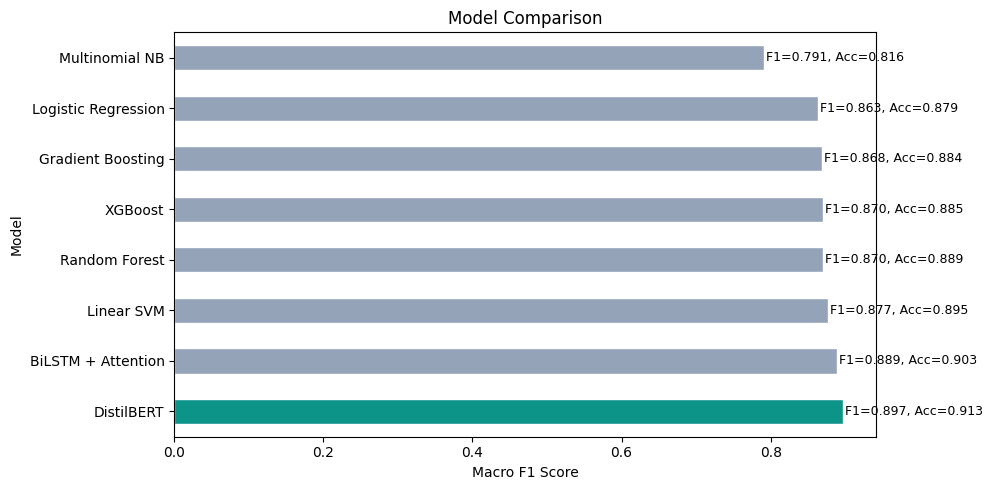

In [22]:
# gather all results
all_scores = {}
for name, res in ml_results.items():
    all_scores[name] = {'Accuracy': res['acc'], 'Macro F1': res['f1']}
all_scores['BiLSTM + Attention'] = {'Accuracy': acc_lstm, 'Macro F1': f1_lstm}
all_scores['DistilBERT'] = {'Accuracy': acc_bert, 'Macro F1': f1_bert}

results_df = pd.DataFrame(all_scores).T.sort_values('Macro F1', ascending=False)
results_df.index.name = 'Model'
print(results_df.to_string(float_format=lambda x: f"{x:.4f}"))

# bar chart
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#0d9488' if i == 0 else '#94a3b8' for i in range(len(results_df))]
results_df['Macro F1'].plot(kind='barh', ax=ax, color=colors, edgecolor='white')
ax.set_xlabel('Macro F1 Score')
ax.set_title('Model Comparison')
for i, (f1, acc) in enumerate(zip(results_df['Macro F1'], results_df['Accuracy'])):
    ax.text(f1 + 0.003, i, f"F1={f1:.3f}, Acc={acc:.3f}", va='center', fontsize=9)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/comparison.png", dpi=150, bbox_inches='tight')
plt.show()

results_df.to_csv(f"{OUTPUT_DIR}/model_comparison.csv")

In [23]:
# save metadata and list all artifacts
best_overall = results_df.index[0]
best_f1_overall = results_df.iloc[0]['Macro F1']

with open(f"{OUTPUT_DIR}/model_metadata.txt", "w") as f:
    f.write(f"best_model: {best_overall}\n")
    f.write(f"macro_f1: {best_f1_overall:.4f}\n")
    f.write(f"classes: {list(le.classes_)}\n")
    f.write(f"train_size: {len(X_train)}\n")
    f.write(f"test_size: {len(X_test)}\n")

print(f"Best overall: {best_overall} (F1 = {best_f1_overall:.4f})")
print(f"\nAll saved artifacts:")
for item in sorted(os.listdir(OUTPUT_DIR)):
    path = os.path.join(OUTPUT_DIR, item)
    if os.path.isfile(path):
        print(f"  {item:<40s} {os.path.getsize(path)/1024:>8.1f} KB")
    else:
        total = sum(os.path.getsize(os.path.join(path, f))
                    for f in os.listdir(path) if os.path.isfile(os.path.join(path, f)))
        print(f"  {item + '/':<40s} {total/1024/1024:>8.1f} MB")

print(f"\nDownload from: {OUTPUT_DIR}/")

Best overall: DistilBERT (F1 = 0.8970)

All saved artifacts:
  best_ml_model.joblib                       2346.7 KB
  bilstm_best.pth                            8784.1 KB
  bilstm_cm.png                                55.0 KB
  bilstm_curves.png                            72.7 KB
  bilstm_vocab.joblib                         147.0 KB
  comparison.png                               73.5 KB
  distilbert_best/                            256.1 MB
  distilbert_cm.png                            54.6 KB
  distilbert_curves.png                        62.6 KB
  label_encoder.joblib                          0.5 KB
  ml_confusion_matrices.png                   241.0 KB
  model_comparison.csv                          0.4 KB
  model_metadata.txt                            0.1 KB
  tfidf_vectorizer.joblib                     818.3 KB

Download from: /kaggle/working/saved_models/


In [24]:
# quick inference demo to show the pipeline works end-to-end
print("Inference demo (using best ML model):\n")

test_addresses = [
    "Flat no 405, 3rd Floor, Shivani Apartment, Kothrud, Pune",
    "Plot number 88, survey no 123/A, Green Layouts, Bangalore",
    "Survey 99/2, Agricultural Land, Village Chakan, Taluka Khed",
    "Shop No 7, Ground Floor, Phoenix Mall, MG Road, Mumbai",
    "Municipal Primary Health Center, Ward 3, Village Karjat",
]

best_ml = ml_results[best_ml_name]['model']
cleaned = [clean_address(a) for a in test_addresses]
predictions = le.inverse_transform(best_ml.predict(tfidf.transform(cleaned)))

for addr, pred in zip(test_addresses, predictions):
    print(f"  {pred:>16s}  |  {addr}")

Inference demo (using best ML model):

              flat  |  Flat no 405, 3rd Floor, Shivani Apartment, Kothrud, Pune
       houseorplot  |  Plot number 88, survey no 123/A, Green Layouts, Bangalore
        landparcel  |  Survey 99/2, Agricultural Land, Village Chakan, Taluka Khed
   commercial unit  |  Shop No 7, Ground Floor, Phoenix Mall, MG Road, Mumbai
            others  |  Municipal Primary Health Center, Ward 3, Village Karjat
